# Klasyfikacja
## Dzielenie danych na zbiór treningowy i testowy

In [19]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

iris = pd.read_csv("iris.csv")
X = iris.drop(columns="variety")
y = iris.variety

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=1)

## Tworzenie modelu i testowanie

In [20]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        17
  Versicolor       0.95      1.00      0.97        19
   Virginica       1.00      0.93      0.96        14

    accuracy                           0.98        50
   macro avg       0.98      0.98      0.98        50
weighted avg       0.98      0.98      0.98        50



## Zadania
1. Przypisz następujące przykłady do klasy A lub B przy użyciu metody k-NN z k=3. 
    - Zbiór treningowy: A(1, 3), A(2, 1), A(2, 3), B(4, 3), B(6, 3).
    - Przykłady do zaklasyfikowania: (1, 5), (5, 1), (2, 6), (3, 4).


In [21]:
# Zadanie 1:
# To zadanie tablicowe - może być na kolokwium, przeprowadzane w grupach, do przećwiczenia w domu.

2. Użyj zbioru treningowego z `Playgolf.xlsx` do klasyfikacji następujących przykładów klasyfikatorem Naive Bayes. Tam, gdzie to konieczne, stosuj wygładzanie $\frac{x_i+1}{N+d}$:
    - (sunny, cool, high, true).
    - (overcast, mild, normal, false).


In [22]:
# Zadanie 2:
# To też zadanie tablicowe - może być na kolokwium, przeprowadzane w grupach, do przećwiczenia w domu.

3. Klasyfikuj przypadki ze zbioru `wdbc.data` jako `M` - *malignant* lub `B` - *benign*.
    - Podziel dane na zbiór treningowy i testowy. Ze zbioru treningowego wydziel dodatkowo zbiór walidacyjny.
    - Użyj k-NN do klasyfikacji przykładów ze zbioru walidacyjnego na podstawie pozostałych danych treningowych i wypisz dokładność, precyzję, pełność, F-miarę. Warto wypisać też macierz omyłek ([`confusion_matrix()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)).
    - Sprawdź, jaki wpływ na dokładność ma skalowanie danych: [`MinMaxScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html), [`minmax_scale()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.minmax_scale.html). Pamiętaj, że skalować należy także dane walidacyjne/testowe.
    - Porównaj dokładność k-NN i regresji logistycznej ([`LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)).
    - Stwórz wykres zależności dokładności od k. Skorzystaj ze zbioru walidacyjnego.
    - Wybierz najlepszy model i podaj jego dokładność dla danych testowych.


Bez skalowania, k=5: 92.98%
MinMaxScaler, k=5: 97.37%


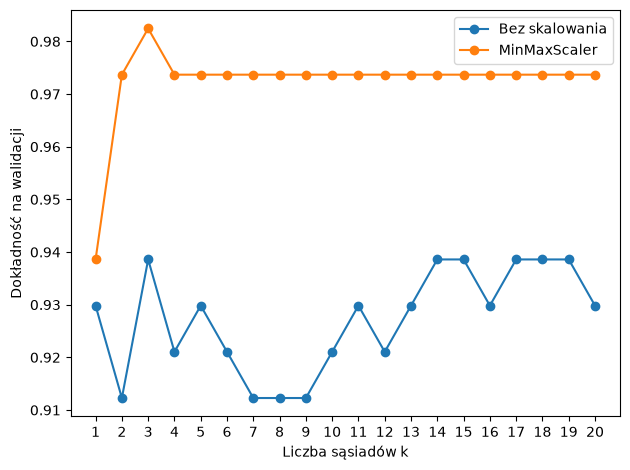

Raport walidacyjny dla k-NN (MinMaxScaler, k=3)
              precision    recall  f1-score   support

           B       0.97      1.00      0.99        71
           M       1.00      0.95      0.98        43

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Macierz błędów (kolejność klas B, M)
[[71  0]
 [ 2 41]]
k-NN (Bez skalowania, k=3), walidacja: 93.86%
k-NN (MinMaxScaler, k=3), walidacja: 98.25%
Regresja logistyczna (MinMaxScaler), walidacja: 97.37%
Wybrany model: k-NN (MinMaxScaler, k=3)
Dokładność na teście: 95.61%


In [23]:
# Zadanie 3
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler

# Wczytuję dane
data = pd.read_csv("wdbc.data")

X = data.drop(columns="diagnosis")
y = data["diagnosis"]

# Podział na zbiór treningowy, walidacyjny i testowy
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

k_values = range(1, 21) # W pętli sprawdzam wartości k dla KNN
candidates = {}
for label in ("Bez skalowania", "MinMaxScaler"): # Oznaczam skalowanie
    scores = []
    models = []
    for k in k_values:
        model = KNeighborsClassifier(n_neighbors=k)
        # Pipeline dopasowuje skaler na treningu i stosuje go przy predykcji.
        if label == "MinMaxScaler":
            model = make_pipeline(MinMaxScaler(), model)
        model.fit(X_train, y_train)
        models.append(model)
        scores.append(model.score(X_val, y_val))

    plt.plot(k_values, scores, marker="o", label=label)
    print(f"{label}, k=5: {scores[4]:.2%}")
    best_index = scores.index(max(scores))
    name = f"k-NN ({label}, k={k_values[best_index]})"
    candidates[name] = models[best_index]

# Porównanie wpływu skalowania na dokładność kNN
plt.xlabel("Liczba sąsiadów k")
plt.ylabel("Dokładność na walidacji")
plt.xticks(k_values)
plt.legend()
plt.tight_layout()
plt.show()

best_knn = max(candidates, key=lambda name: candidates[name].score(X_val, y_val))
print(f"Raport walidacyjny dla {best_knn}")
y_pred = candidates[best_knn].predict(X_val)
print(classification_report(y_val, y_pred, labels=["B", "M"]))
print("Macierz błędów (kolejność klas B, M)")
print(confusion_matrix(y_val, y_pred, labels=["B", "M"]))

# Liczę regresję logistyczną by mieć porównanie
logistic = make_pipeline(MinMaxScaler(), LogisticRegression())
logistic.fit(X_train, y_train)
candidates["Regresja logistyczna (MinMaxScaler)"] = logistic
scores = {name: model.score(X_val, y_val) for name, model in candidates.items()}
for name, score in scores.items():
    print(f"{name}, walidacja: {score:.2%}")

# Po wyborze modelu uczę go ponownie na treningowym i walidacyjnym razem:
best_name = max(scores, key=scores.get)
best_model = candidates[best_name]
best_model.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
print(f"Wybrany model: {best_name}") # Wybrany model to kNN z k = 3 i skalowanie MinMaxScaler
print(f"Dokładność na teście: {best_model.score(X_test, y_test):.2%}") # Dokładność na teście: 95.61%


4. Klasyfikuj grzyby ze zbioru `agaricus-lepiota.data` jako trujące (`p` - *poisonous*) lub jadalne (`e` - *edible*) za pomocą [`CategoricalNB`](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.CategoricalNB.html).
    - Brakujące wartości zapisane są w zbiorze jako `?` (wczytując dane podaj `na_values='?'`). Usuń wiersze zawierające brakujące wartości (`dropna(axis='rows')`).
    - Dane wejściowe (`X`) koduj jako 0,1,2,... przy użyciu [`OrdinalEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html).
    - Podziel dane na zbiór treningowy i testowy. Wypisz macierz omyłek oraz dokładność i F-miarę dla zbioru testowego.


In [24]:
# Zadanie 4
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import f1_score

# Wczytuję dane i usuwam wiersze z brakującymi wartościami
data = pd.read_csv("agaricus-lepiota.data", na_values="?").dropna(axis="rows")

X = data.drop(columns="class")
y = data["class"]

# Podział na zbiór treningowy i testowy
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Koduję dane wejściowe za pomocą OrdinalEncoder
model = make_pipeline(OrdinalEncoder(dtype=int), CategoricalNB())
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Macierz omyłek (kolejność klas e, p)")
print(confusion_matrix(y_test, y_pred, labels=["e", "p"]))
print(f"Dokładność na teście: {model.score(X_test, y_test):.2%}")
print(f"F1 na teście (klasa trująca): {f1_score(y_test, y_pred, pos_label='p'):.2%}")

# sprawdź trująca jako jadalne

Macierz omyłek (kolejność klas e, p)
[[696   2]
 [ 31 400]]
Dokładność na teście: 97.08%
F1 na teście (klasa trująca): 96.04%


5. (Bonus) Klasyfikuj wiadomości email ze zbioru `spamham.csv` jako `spam` lub `ham`.
    - Sprawdź w dokumentacji [`CountVectorizer`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html), jak przekształcić teksty na wektory zawierające liczbę wystąpień słów.
    - Podziel dane na zbiór treningowy i testowy.
    - Użyj [`MultinomialNB`](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html) aby klasyfikować wiadomości. Wypisz dokładność na zbiorze testowym.

In [25]:
# Zadanie 5
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

data = pd.read_csv("spamham.csv")
X = data["email_text"]
y = data["is_spam"].map({True: "spam", False: "ham"})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(CountVectorizer(), MultinomialNB())
model.fit(X_train, y_train)

print(f"Dokładność na teście: {model.score(X_test, y_test):.2%}")

Dokładność na teście: 98.00%
